# Example 1: I have RQ files and want a plot

*An example for the `goldpan` / `goldsluice` note. Draft prepared with Claude Code for A. Villano, 2026-10-29.*

**The goal.** You have RQ files (the reduced quantities of a series, one ROOT file per dump, in the layout of the collaboration's `rqDir/eventTree` and `rqDir/zip<N>`). How they were made does not matter here. Read them with `goldpan` and draw the distribution of one quantity.

**The data here are made up.** `synthetic-rq/` holds two small ROOT files (24 events), so the notebook runs on a fresh clone. To use your own files, change `DATA` and `DETECTOR` in the second cell; the names in the plot cell come from your files (the cell before it prints them).

Needs `uproot` and `goldpan` (both in `requirements.txt`). Run with the `darkmatter_cli_env` kernel.

In [1]:
import sys
from pathlib import Path

import awkward as ak
import matplotlib.pyplot as plt
import numpy as np

from goldpan.adapters import rq_root

In [2]:
# Where the RQ files are, and which detector's quantities to read (never assumed: it is the N of rqDir/zip<N> in the files).
DATA = Path("synthetic-rq")          # a folder of .root files, or one file
DETECTOR = 1

if not list(DATA.glob("*.root")):     # the synthetic files are rewritten from the test generator if they are missing
    _here = Path.cwd().resolve()
    REPO = next(p for p in [_here, *_here.parents] if (p / "python" / "tests" / "synthetic_series.py").exists())
    sys.path.insert(0, str(REPO / "python" / "tests"))
    import synthetic_series as ss
    for dump in ss.all_dumps():
        ss.write_rq_root(dump, DATA)

In [3]:
# Read them: one table, one record per event; the event key (series, dump, event) comes first. A folder is read file after file.
table = rq_root.read(DATA, detector=DETECTOR)

print(len(table), "events;", len(ak.fields(table)), "fields")
print(ak.fields(table))

24 events; 27 fields
['series', 'dump', 'event', 'DumpNumber', 'EventNumber', 'EventType', 'PTOFamps', 'PTOFdelay', 'TriggerDetectorNum', 'Side2pAmax', 'Side2pAmaxbin', 'Side2pAstd', 'Side2pBmax', 'Side2pBmaxbin', 'Side2pBstd', 'Side2pCmax', 'Side2pCmaxbin', 'Side2pCstd', 'Side2pDmax', 'Side2pDmaxbin', 'Side2pDstd', 'Side2pEmax', 'Side2pEmaxbin', 'Side2pEstd', 'Side2pFmax', 'Side2pFmaxbin', 'Side2pFstd']


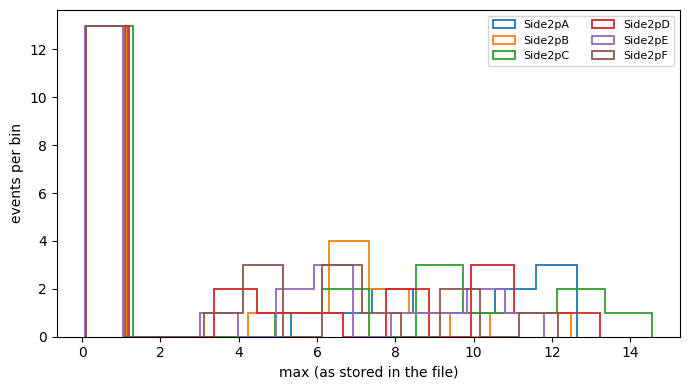

In [4]:
# One quantity for every channel: a column of the table is a numpy array.
quantity = "max"                                             # the quantity; the fields are <channel><quantity>
channels = sorted({f[:-len(quantity)] for f in ak.fields(table) if f.startswith("Side2p") and f.endswith(quantity)})

fig, ax = plt.subplots(figsize=(7, 4))
for ch in channels:
    v = ak.to_numpy(table[ch + quantity]).astype(float)
    ax.hist(v[np.isfinite(v)], bins=12, histtype="step", lw=1.3, label=ch)     # NaN: the channel was not read out in that event
ax.set_xlabel(f"{quantity} (as stored in the file)")
ax.set_ylabel("events per bin")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

**What this shows.** `rq_root.read` gives a table and a histogram of an RQ is a `numpy` histogram of one of its columns. Next scenarios: cuts on the RQs, and putting the RQs on top of the traces they describe.